In [ ]:
import numpy as np
num_matrices = 2500
def getLv(ell, K, R, num_matrices):
    L_v_tensor = np.ones((num_matrices, K, ell), dtype=bool)
    false_ratios = np.linspace(0, 1, 50)  # Define the required false ratio sequence
    false_ratio_permutations = np.array(np.meshgrid(false_ratios, false_ratios)).T.reshape(-1, 2)  # Get all pairwise permutations

    for m in range(num_matrices):
        L_v = np.ones((K, ell), dtype=bool)

        # Ensure L_v[0] has approximately 50% False
        L_v[0, np.random.choice(ell, size=int(0.9 * ell), replace=False)] = False

        # Select a false ratio permutation
        ratio_index = m % len(false_ratio_permutations)
        false_ratio_1, false_ratio_2 = false_ratio_permutations[ratio_index]

        # Apply false ratios to L_v[1] and L_v[2]
        num_false_1 = int(false_ratio_1 * ell)
        num_false_2 = int(false_ratio_2 * ell)

        L_v[1, np.random.choice(ell, size=num_false_1, replace=False)] = False
        L_v[2, np.random.choice(ell, size=num_false_2, replace=False)] = False

        L_v_tensor[m] = L_v

    return L_v_tensor

In [ ]:
def normalize_kernel(K):
    """
    Normalizes the kernel matrix so that the diagonal entries are 1.

    Parameters:
        K (np.ndarray): A positive definite kernel matrix.

    Returns:
        np.ndarray: The normalized kernel matrix.
    """
    # Compute the square root of the diagonal elements
    diag = np.sqrt(np.diag(K))
    # Outer product of diag with itself
    norm_factor = np.outer(diag, diag)
    # Elementwise division to normalize
    K_normalized = K / norm_factor
    return K_normalized

def compute_kernel_distance(K):
    # Apply the formula; since K is a numpy array, we use it directly.
    D_squared = 2 * (1 - K)
    # Ensure non-negative values (for numerical stability)
    D_squared[D_squared < 0] = 0
    # Take the square root to get the distance matrix
    D = np.sqrt(D_squared)
    return D

In [ ]:
import numpy as np
import gudhi as gd
from scipy.sparse import dok_matrix

def compute_rips_from_distance_matrix(distance_matrix, max_edge_length):
    rips_complex = gd.RipsComplex(distance_matrix=distance_matrix, max_edge_length=max_edge_length)
    simplex_tree = rips_complex.create_simplex_tree(max_dimension=2)
    return simplex_tree

def extract_simplices(filtration):
    simplices = {'vertices': [], 'edges': [], 'faces': []}
    for simplex, _ in filtration:
        if len(simplex) == 1:
            simplices['vertices'].append(simplex)
        elif len(simplex) == 2:
            simplices['edges'].append(simplex)
        elif len(simplex) == 3:
            simplices['faces'].append(simplex)
    return simplices

def get_boundary_matrix(simplices_higher, simplices_lower):
    if not simplices_higher or not simplices_lower:
        return None
    n_higher = len(simplices_higher)
    n_lower = len(simplices_lower)
    boundary_matrix = dok_matrix((n_lower, n_higher), dtype=int)
    simplex_to_index = {tuple(simplex): i for i, simplex in enumerate(simplices_lower)}
    for j, higher_simplex in enumerate(simplices_higher):
        for i, vertex in enumerate(higher_simplex):
            boundary_simplex = tuple(sorted(higher_simplex[:i] + higher_simplex[i+1:]))
            if boundary_simplex in simplex_to_index:
                row_index = simplex_to_index[boundary_simplex]
                boundary_matrix[row_index, j] = (-1) ** i
    return boundary_matrix

def compute_laplacian(boundary_prev, boundary_next):
    laplacian = None
    if boundary_prev is not None:
        laplacian = boundary_prev.transpose().dot(boundary_prev)
    if boundary_next is not None:
        if laplacian is None:
            laplacian = boundary_next.dot(boundary_next.transpose())
        else:
            laplacian += boundary_next.dot(boundary_next.transpose())
    return laplacian

def compute_eigenvalues(laplacian):
    if laplacian is not None:
        _, singular_values, _ = np.linalg.svd(laplacian.toarray())
        return np.sort(singular_values)
    return None

def eigenvalues_above_mean(distance_matrix, max_edge_length):
    simplex_tree = compute_rips_from_distance_matrix(distance_matrix, max_edge_length)
    filtration = list(simplex_tree.get_filtration())
    simplices = extract_simplices(filtration)

    boundary_1 = get_boundary_matrix(simplices['edges'], simplices['vertices'])
    laplacian_0 = compute_laplacian(None, boundary_1)

    if laplacian_0 is not None:
        eigenvalues_0 = compute_eigenvalues(laplacian_0)
        mean_eigenvalue = np.mean(eigenvalues_0)
        #count_above_mean = np.sum(eigenvalues_0 > mean_eigenvalue)
        count_above_mean = np.sum(eigenvalues_0 <= 1e-10)
        return mean_eigenvalue, count_above_mean


In [ ]:
import numpy as np

def is_pos_def(matrix):
    return np.all(np.linalg.eigvals(matrix) > 0)

def get_inc_kerns(kernmats, L_v):
    ell, _, K = kernmats.shape
    Q_inc = np.zeros((ell, ell, K))

    for k in range(K):
        l_tmp1 = L_v[k, :]
        Q_inc[np.ix_(l_tmp1, l_tmp1, [k])] = kernmats[np.ix_(l_tmp1, l_tmp1, [k])]
        if not is_pos_def(Q_inc[:, :, k]):
            Q_inc[:, :, k] += 0.001 * np.eye(ell)

    return Q_inc

np.random.seed(42)  # For reproducibility

def get_model(Q, Lambda):
    N, _, K = Q.shape
    Beta = 1 / (K + Lambda)
    M = Beta * (np.sum(Q, axis=2) + Lambda * np.eye(N))

    if not is_pos_def(M):
        M += 0.001 * np.eye(N)

    return M

def get_UL(S):
    eigval, eigvec = np.linalg.eigh(S)
    idx = np.argsort(eigval)[::-1]  # Sort in descending order
    return eigvec[:, idx], eigval[idx]

def mkmc(Qtmp, L_v, Lambda, Mtmp, niters):
    _, _, K = Qtmp.shape
    for _ in range(niters):
        for k in range(K):
            Qk = Qtmp[:, :, k]
            if not is_pos_def(Qk):
                Qk += 0.001 * np.eye(Qk.shape[0])

            l_v = L_v[k, :]
            l_h = ~l_v
            Qvv = Qk[np.ix_(l_v, l_v)]
            Mvv = Mtmp[np.ix_(l_v, l_v)]
            Mvh = Mtmp[np.ix_(l_v, l_h)]
            Mhh = Mtmp[np.ix_(l_h, l_h)]

            Qvh = Qvv @ np.linalg.solve(Mvv, Mvh)
            Qhh = Mhh - (Mvh.T @ np.linalg.solve(Mvv, Mvh)) + (Mvh.T @ np.linalg.solve(Mvv, Qvv @ np.linalg.solve(Mvv, Mvh)))

            Qk[np.ix_(l_v, l_h)] = Qvh
            Qk[np.ix_(l_h, l_v)] = Qvh.T
            Qk[np.ix_(l_h, l_h)] = Qhh
            Qtmp[:, :, k] = Qk

        Mtmp = get_model(Qtmp, Lambda)

    return Qtmp

def pcagk_psa(Qtmp, Lambda, L_v):
    #Performs PCA-based Gaussian Kernel completion.
    ell, _, _ = Qtmp.shape
    Mtmp = get_model(Qtmp, Lambda)

    for _ in range(10):
        Qpca = mkmc(Qtmp, L_v, Lambda, Mtmp, 1)
        Smat = get_model(Qpca, Lambda)
        Smat_norm = normalize_kernel(Smat)
        Smat_dist = compute_kernel_distance(Smat_norm)

        float_value, q = map(lambda x: x.item(), eigenvalues_above_mean(Smat_dist, np.max(Smat_dist)))
        #print(float_value)

        U, L = get_UL(Smat)
        sigma2 = np.mean(L[q:])

        W = U[:, :q] @ np.sqrt(np.diag(L[:q]) - sigma2 * np.eye(q))
        Mtmp = W @ W.T + sigma2 * np.eye(ell)
        Qtmp = Qpca

    return Qpca

np.random.seed(42)
ell = 20  # Adjust as needed
K = 3
R = 0.3
L_v_tensor = getLv(ell, K, R, num_matrices)

kernmats = np.zeros((ell, ell, K))
for k in range(K):
    A = np.random.rand(ell, ell)
    kernmats[:, :, k] = A @ A.T  # Construct symmetric PD matrix

proportion = []
Lambda = 0.001
Qpca_results = []
for i in range(num_matrices):
    L_v = L_v_tensor[i]
    missed = np.sum(L_v == False, axis=1) / ell
    Qzero = get_inc_kerns(kernmats, L_v)
    Mzero = get_model(Qzero, Lambda)
    Qpca = pcagk_psa(Qzero, Lambda, L_v)
    Qpca_results.append(Qpca)
    proportion.append(missed[1:3])

In [ ]:
corr_norm = []
for j in range(num_matrices):
  diff = 0
  for k in range(K):
    diff += 1- ((np.trace(np.matmul(kernmats[:,:,k],Qpca_results[j][:,:,k])))/(np.linalg.norm(kernmats[:,:,k], 'fro')*np.linalg.norm(Qpca_results[j][:,:,k], 'fro')))
  diff = diff/K
  #missed = np.sum(L_v_tensor[j] == False, axis=1) / ell
  corr_norm.append(diff)

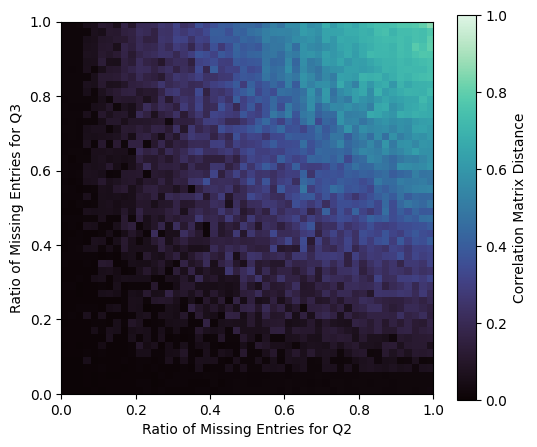

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Given data
proportions = np.array(proportion)
weights = np.array(corr_norm)

# Extract x and y values
x = proportions[:, 0]
y = proportions[:, 1]

# Define grid size
grid_size = (50, 50)
density_map = weights.reshape(grid_size)

# Plot using imshow with intensity range 0 to 1
plt.figure(figsize=(6, 5))
img = plt.imshow(density_map.T, extent=[0, 1, 0, 1], origin='lower', cmap='mako', vmin=0, vmax=1)

# Add colorbar with limits
cbar = plt.colorbar(img)
cbar.set_label('Correlation Matrix Distance')

# Labels and title
plt.xlabel('Ratio of Missing Entries for Q2')
plt.ylabel('Ratio of Missing Entries for Q3')
# plt.title('Density map')

# Show plot
plt.show()
